# ICARUS: what does a solar storm cost an orbit?

Final notebook of the ICARUS project (Advanced Data Analytics). It walks through the whole study in order:
data, storms, physics baseline, then the three research questions and their checks. Every number is computed
here from the files in `data/processed/` and the saved results, by calling the functions in `src/`; nothing is typed by hand.

1. **Q1.** How much extra orbital decay do geomagnetic storms cause, and how much of it does the MSIS 2.1 air-density model miss?
2. **Q2.** Which objects are hit hardest (altitude, inclination, drag sensitivity)?
3. **Q3.** How much of the storm's damage do satellite operators (Starlink) undo?

## 0. Setup and how to run

The notebook needs the processed data (`data/processed/`, shared via Drive) and runs no downloads. With `FAST = True`
every step that takes more than 5 minutes (building the analysis table, the event study, double ML and its refutations,
the causal forests) is loaded from its saved output in `results/causal/` and `results/dml/`; everything else is recomputed.
With `FAST = False` the slow steps are rerun first (several hours) and overwrite those saved outputs.

Run it top to bottom from a fresh kernel, from the repository root:

    python -m jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 notebooks/ICARUS_final.ipynb

In [1]:
FAST = True   # True: load the saved results of the slow steps (> 5 min); False: recompute everything

import contextlib
import io
import os
import re
import sys
import tempfile
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # started from notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
T_START = time.time()
TIMES = {}
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import review_figures as rf     # the review figure pack: each figure returns (figure, key numbers)
import matplotlib.pyplot as plt
%matplotlib inline
rf.set_style()
plt.rcParams["figure.dpi"] = 90

from src import (build_table, causal_run, dml_refute, dml_run, extreme_check, physics, schema,
                 sensitivity, storm_class, vulnerability_map)
from src.storms import load_storms

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
PROCESSED, CAUSAL, DML, REVIEW = ROOT / "data/processed", ROOT / "results/causal", ROOT / "results/dml", ROOT / "results/review"
N = {}          # key numbers, same keys as src/review_figures.main, checked against SUMMARY.md in section 10


def show(fig):
    # show a figure once and free it
    display(fig)
    plt.close(fig)


def slow_step(name, outputs, recompute):
    # A step that takes more than 5 minutes. FAST: use its saved outputs. Otherwise rerun it (it rewrites them).
    t = time.time()
    if FAST:
        missing = [str(p) for p in outputs if not Path(p).exists()]
        assert not missing, f"{name}: saved output missing, rerun with FAST = False: {missing}"
        print(f"{name}: saved results loaded ({len(outputs)} files)")
    else:
        recompute()
        print(f"{name}: recomputed in {(time.time() - t) / 60:.1f} min")
    TIMES[name] = time.time() - t


def timed(name, fn):
    # A fast step, always recomputed here.
    t = time.time()
    out = fn()
    TIMES[name] = time.time() - t
    return out


print("FAST =", FAST, "| repository:", ROOT)

FAST = True | repository: C:\Users\akash\Documents\ADA_paper


## 1. Data and cleaning counts

The cohort is 250 passive objects (debris and rocket bodies) at 400-800 km plus 15 high-altitude controls
(1,040-1,211 km) and 26 active satellites (25 Starlink) for Q3. Each row of the analysis table is one decay interval:
the change in Brouwer mean semi-major axis between two cleaned TLEs. Cleaning drops duplicate epochs and bad TLEs,
flags passive "climbs" and Hampel outliers of the model residual, and never lets an interval cross a storm onset.

In [2]:
slow_step("build analysis table", [PROCESSED / "analysis_table.parquet"], lambda: build_table.main([]))
table = timed("load table", schema.load_table)          # schema-validated
intervals = pd.read_parquet(PROCESSED / "orbit_intervals_a2_a4.parquet")
tles = pd.read_parquet(extreme_check.TLES_PATH)
objects = pd.read_parquet(PROCESSED / "objects.parquet")

passive = table[table["is_active"] == 0]
counts = pd.Series({
    "cleaned TLEs (passive cohort)": len(tles),
    "passive objects": tles["norad_id"].nunique(),
    "decay intervals (passive)": len(intervals),
    "  of which main cohort (400-800 km)": int((intervals["cohort_group"] == "main").sum()),
    "  of which high-altitude control": int((intervals["cohort_group"] == "high_altitude").sum()),
    "  passive climbs (kept, climb_flag = 1)": int(intervals["climb_flag"].sum()),
    "Hampel outliers (tle_ok = 0)": int(passive["hampel_outlier"].sum()),
    "active-satellite intervals": int((table["is_active"] == 1).sum()),
    "analysis table rows": len(table),
    "analysis table objects": table["norad_id"].nunique(),
}, name="count")
display(counts.to_frame().style.format("{:,}"))
print("Object types:", objects["object_type"].value_counts().to_dict(), "| active:", int(objects["is_active"].sum()))
print(f"Hampel outliers: {passive['hampel_outlier'].mean():.1%} of passive rows")
display(Markdown("**Main-sample filters, applied in order** (`schema.sample_report`)"))
display(schema.sample_report(table).style.format({"removed": "{:,}", "share": "{:.1%}"}))

build analysis table: saved results loaded (1 files)


,count
cleaned TLEs (passive cohort),"205,145"
passive objects,265
decay intervals (passive),"199,580"
of which main cohort (400-800 km),"188,560"
of which high-altitude control,"11,020"
"passive climbs (kept, climb_flag = 1)","4,705"
Hampel outliers (tle_ok = 0),"11,005"
active-satellite intervals,"19,900"
analysis table rows,"219,480"
analysis table objects,291


Object types: {'debris': 149, 'rocket body': 116, 'payload': 26} | active: 26
Hampel outliers: 5.5% of passive rows


**Main-sample filters, applied in order** (`schema.sample_report`)

,filter,removed,share
0,active satellite,"19,900",9.1%
1,high-altitude control (alt >= 1000 km),"11,020",5.0%
2,ecc >= 0.01,0,0.0%
3,TLE failed cleaning,"10,453",4.8%
4,no drag_sensitivity,0,0.0%
5,kept,"178,107",81.1%


## 2. Space weather and the 20-storm catalogue

Hourly OMNI2 space weather (ap, Dst, F10.7 and its 81-day mean) covers April 2024 to April 2025. A storm is any
Dst dip below -50 nT; the 20 storms are classed moderate, strong, severe or extreme, and the main-phase onset is day 0.
Figure 1 shows what the biggest storm (May 2024) did to the decay rate of the whole cohort.

Space weather: 9,480 hours, 2024-04-01 to 2025-04-30; F10.7 112-345 sfu; ap max 400


,class,min_dst,main_onset,peak_time,recovery_end
storm_id,,,,,
1,strong,-117.0,2024-04-19 00:00:00,2024-04-19 19:00:00,2024-04-22 08:00:00
2,moderate,-51.0,2024-04-25 19:00:00,2024-04-26 16:00:00,2024-04-27 01:00:00
3,moderate,-89.0,2024-05-02 09:00:00,2024-05-02 19:00:00,2024-05-03 13:00:00
4,extreme,-406.0,2024-05-10 17:00:00,2024-05-11 02:00:00,2024-05-19 10:00:00
5,strong,-107.0,2024-06-27 17:00:00,2024-06-28 12:00:00,2024-06-29 20:00:00
6,moderate,-100.0,2024-08-03 19:00:00,2024-08-04 17:00:00,2024-08-05 07:00:00
7,strong,-188.0,2024-08-11 19:00:00,2024-08-12 16:00:00,2024-08-14 13:00:00
8,moderate,-76.0,2024-08-27 09:00:00,2024-08-28 06:00:00,2024-09-01 07:00:00
9,strong,-121.0,2024-09-12 04:00:00,2024-09-12 14:00:00,2024-09-20 02:00:00


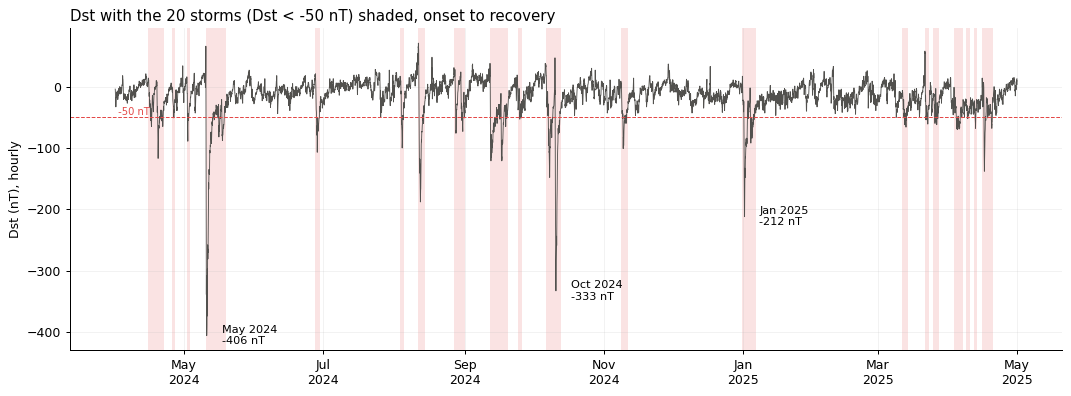

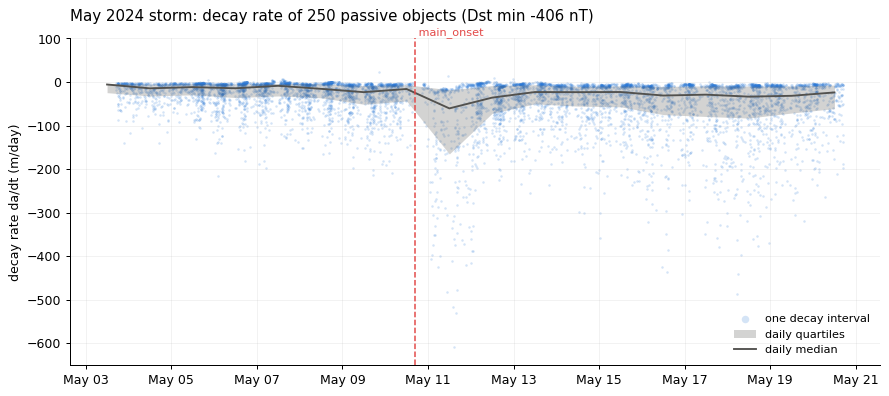

Fig 1: median decay -18 -> -60 m/day, 3.4x


In [3]:
sw = pd.read_parquet(PROCESSED / "spaceweather.parquet")
if "time" in sw.columns:
    sw = sw.set_index("time")
storms = load_storms()
print(f"Space weather: {len(sw):,} hours, {sw.index.min():%Y-%m-%d} to {sw.index.max():%Y-%m-%d}; "
      f"F10.7 {sw['f107'].min():.0f}-{sw['f107'].max():.0f} sfu; ap max {sw['ap'].max():.0f}")
display(storms[["storm_id", "class", "min_dst", "main_onset", "peak_time", "recovery_end"]].set_index("storm_id"))
fig, N["catalog"] = rf.fig_storm_catalog(sw, storms)
show(fig)
fig, N["may"] = rf.fig_may_cohort(table, storms)
show(fig)
print(f"Fig 1: median decay {N['may']['before']:.0f} -> {N['may']['after']:.0f} m/day, {N['may']['ratio']:.1f}x")

## 3. Physics baseline, drag sensitivity, the two outcomes and validation

For every interval we predict the decay from MSIS 2.1 air density (NRLMSISE-00 as a check) times one drag sensitivity B
per object, fitted on quiet days. Two outcomes follow: **Y_total** = observed decay minus the prediction with the storm's
pre-storm quiet ap (the total storm effect) and **Y_residual** = observed minus the prediction with the actual ap (the model's error).
The baseline is checked on held-out quiet intervals, against catalog area-to-mass and against precise orbits (GRACE-FO, Swarm).

Drag sensitivity B (m^2/kg): 265 passive objects, median 0.0293, range 0.0056-0.8859; sources {'fit': 265}; unstable fits 0


,count,mean,std,min,25%,50%,75%,max
obs_decay,178107.0,-54.10,103.17,-3357.30,-59.47,-19.88,-6.77,1672.33
pred_decay,178107.0,-54.01,96.11,-2447.74,-61.01,-21.01,-6.96,-1.39
Y_total,178107.0,-1.84,29.85,-1420.03,-4.00,-0.16,3.06,1726.47
Y_residual,178107.0,-0.09,27.29,-1006.89,-3.30,0.05,3.52,1793.54


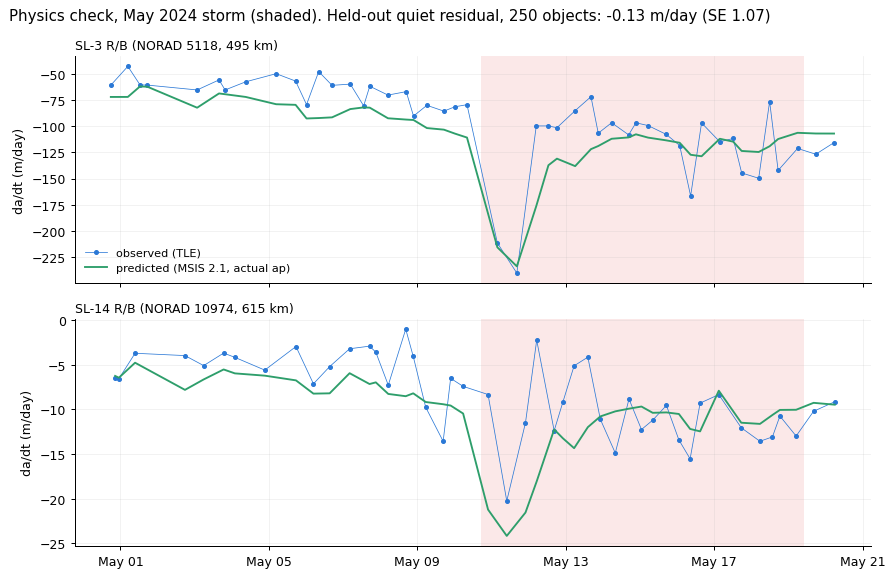

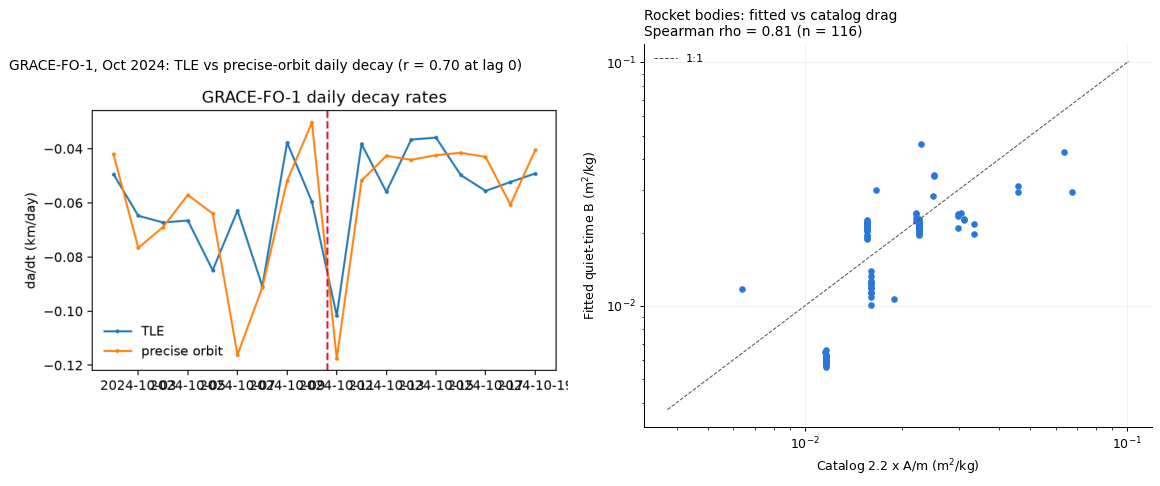

Held-out quiet residual: -0.13 m/day (SE 1.07), 250 objects
Fitted vs catalog drag (rocket bodies): Spearman rho 0.81 (n = 116)
Precise orbits (quoted from the A7 run): GRACE-FO-1 Oct 2024 r = 0.70, Swarm-A r = 0.457


In [4]:
drag = passive.groupby("norad_id").agg(B=("drag_sensitivity", "first"), source=("drag_source", "first"),
                                       unstable=("drag_unstable", "first"), group=("cohort_group", "first"))
print(f"Drag sensitivity B (m^2/kg): {len(drag)} passive objects, median {drag['B'].median():.4f}, "
      f"range {drag['B'].min():.4f}-{drag['B'].max():.4f}; sources {drag['source'].value_counts().to_dict()}; "
      f"unstable fits {int(drag['unstable'].sum())}")
main = schema.main_sample(table)
display(main[["obs_decay", "pred_decay", "Y_total", "Y_residual"]].describe().T.round(2))

fig, N["physics"] = rf.fig_physics_check(table, storms, objects)
show(fig)
fig, N["valid"] = rf.fig_validation(table, objects)
show(fig)
SWARM_R = 0.457    # Swarm-A, zero lag (A7 precise-orbit check, docs/PLAN.md Oct 31; precise-orbit files not in the repo)
print(f"Held-out quiet residual: {N['physics']['holdout']:+.2f} m/day (SE {N['physics']['holdout_se']:.2f}), "
      f"{N['physics']['objects']} objects")
print(f"Fitted vs catalog drag (rocket bodies): Spearman rho {N['valid']['rho']:.2f} (n = {N['valid']['n']})")
print(f"Precise orbits (quoted from the A7 run): GRACE-FO-1 Oct 2024 r = {N['valid']['grace_r']:.2f}, Swarm-A r = {SWARM_R}")

## 4. Q1: event study

A stacked event study compares each object's outcome on days around a storm's onset with day -1, using only storms whose
windows are not contaminated by a neighbouring storm. Inference uses a wild bootstrap clustered by storm, and 500
placebo onset dates. The headline is the days 0-2 effect for both outcomes.

event study + offset model (causal_run): saved results loaded (5 files)


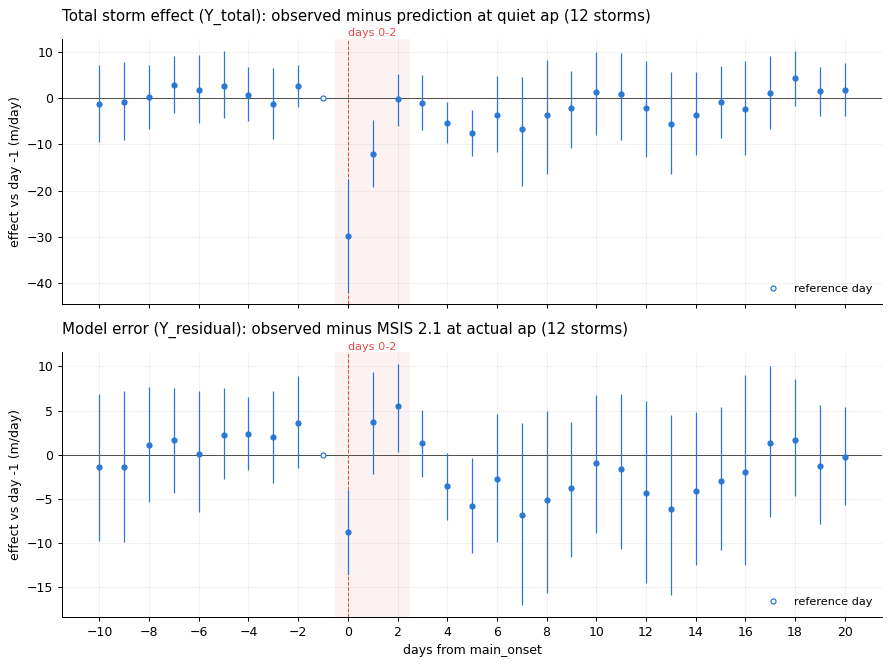

Y_total:
   12 of 20 storms used (8 dropped as contaminated); 117128 of 265350 stacked rows dropped because they fall inside another storm's window.
   Short-run effect (days 0-2, m/day): -14.064 (95% CI -19.751 to -8.401).
   Placebo dates (main inference): 500 draws, mean 0.364, SD 1.270, p = 0.000.
   Pre-trend (RMS of days -10..-2 against the placebo draws): p = 0.410.
   High-altitude negative control: -0.687 (95% CI -1.420 to 0.069), 15 objects, 12 storms.


,est,se,ci_lo,ci_hi,storms_used
all storms,-14.064,3.057,-19.751,-8.401,12.0
"without 3,4,11",-13.845,1.473,-16.625,-10.874,9.0


Y_residual:
   12 of 20 storms used (8 dropped as contaminated); 117128 of 265350 stacked rows dropped because they fall inside another storm's window.
   Short-run effect (days 0-2, m/day): 0.153 (95% CI -3.162 to 3.189).
   Placebo dates (main inference): 500 draws, mean 0.386, SD 1.137, p = 0.876.
   Pre-trend (RMS of days -10..-2 against the placebo draws): p = 0.300.
   High-altitude negative control: -0.174 (95% CI -0.675 to 0.342), 15 objects, 12 storms.


,est,se,ci_lo,ci_hi,storms_used
all storms,0.153,1.630,-3.162,3.189,12.0
"without 3,4,11",-2.218,1.159,-4.347,0.006,9.0


In [5]:
slow_step("event study + offset model (causal_run)",
          [CAUSAL / "summary.md", CAUSAL / "Y_total/event_study.csv", CAUSAL / "Y_residual/event_study.csv",
           CAUSAL / "offset_model.csv", CAUSAL / "offset_model_pairs.csv"],
          lambda: causal_run.main([]))
fig, N["event"] = rf.fig_event_study()
show(fig)
summary_c = (CAUSAL / "summary.md").read_text()
for y in ("Y_total", "Y_residual"):
    sec = summary_c.split(f"## Event study: {y}")[1].split("\n## ")[0]
    print(f"{y}:")
    for line in sec.splitlines():
        if line.startswith("- "):
            print("  ", line[2:])
    display(pd.read_csv(CAUSAL / y / "with_without.csv", index_col=0).round(3))

## 5. Q1: double machine learning (DML), by storm class and by lag

DML estimates the effect of interval-mean ap on the outcome (m/day per nT) after removing F10.7, season, altitude and
local time with cross-fitted helper models; folds and clusters are storms / time blocks. The model-error effect is also
split by storm class, and ap lags of 0, 6, 12 and 24 h are compared (0 h fixed in advance as the main lag).

In [6]:
slow_step("DML (dml_run)", [DML / f"{k}_{y}.csv" for k in ("compare", "lag_sweep") for y in ("Y_total", "Y_residual")],
          lambda: dml_run.main([]))
slow_step("DML refutations (dml_refute, 100 shifts)",
          [DML / f"refute_{k}_{y}.csv" for k in ("high_alt", "random_cc", "placebo", "without", "lags_without")
           for y in ("Y_total", "Y_residual")],
          lambda: dml_refute.main([]))
slow_step("DML by storm class (storm_class)",
          [DML / f"storm_class_dml_{y}.csv" for y in ("Y_total", "Y_residual")]
          + [DML / "storm_class_dml_big_vs_rest_Y_residual.csv"],
          lambda: [storm_class.main(["--outcome", y]) for y in ("Y_residual", "Y_total")])
N["dml"] = rf.dml_numbers()
for y in ("Y_total", "Y_residual"):
    display(Markdown(f"**{y}**: naive, linear and DML (m/day per nT of ap)"))
    display(pd.read_csv(DML / f"compare_{y}.csv", index_col=0)[["coef", "ci_lo", "ci_hi", "n_clusters"]].round(3))
    display(pd.read_csv(DML / f"lag_sweep_{y}.csv", index_col=0)[["coef", "ci_lo", "ci_hi", "model_y"]].round(3))
display(Markdown("**Model error (Y_residual) by storm class, DML**"))
display(pd.read_csv(DML / "storm_class_dml_Y_residual.csv", index_col=0).round(3))
print(f"Severe + extreme vs the rest: exact permutation p = {N['dml']['class_big_p']:.2f}")
display(Markdown(rf.lag_text(N["dml"]["refute"]["Y_residual"])))

DML (dml_run): saved results loaded (4 files)
DML refutations (dml_refute, 100 shifts): saved results loaded (10 files)
DML by storm class (storm_class): saved results loaded (3 files)


**Y_total**: naive, linear and DML (m/day per nT of ap)

,coef,ci_lo,ci_hi,n_clusters
naive,-0.395,-0.542,-0.255,38.0
linear,-0.392,-0.535,-0.261,38.0
dml,-0.393,-0.527,-0.268,38.0
dml_t_linear,-0.393,-0.527,-0.268,38.0
dml_t_xgb_cautious,-0.372,-0.489,-0.256,38.0
dml_t_xgb,-0.302,-0.401,-0.196,38.0


,coef,ci_lo,ci_hi,model_y
lag_hours,,,,
0,-0.393,-0.526,-0.268,xgb_cautious
6,-0.331,-0.449,-0.216,xgb_cautious
12,-0.215,-0.298,-0.128,xgb_cautious
24,-0.060,-0.140,0.021,xgb_cautious


**Y_residual**: naive, linear and DML (m/day per nT of ap)

,coef,ci_lo,ci_hi,n_clusters
naive,-0.060,-0.158,0.036,38.0
linear,-0.054,-0.150,0.040,38.0
dml,-0.050,-0.141,0.047,38.0
dml_t_linear,-0.050,-0.141,0.047,38.0
dml_t_xgb_cautious,-0.044,-0.121,0.033,38.0
dml_t_xgb,-0.050,-0.127,0.025,38.0


,coef,ci_lo,ci_hi,model_y
lag_hours,,,,
0,-0.052,-0.144,0.045,xgb
6,0.003,-0.083,0.098,xgb
12,0.085,-0.004,0.179,xgb
24,0.117,0.035,0.200,xgb


**Model error (Y_residual) by storm class, DML**

,n_storms,n_rows,coef,ci_lo,ci_hi
storm_class,,,,,
moderate,11,45236,-0.133,-0.247,-0.010
strong,6,49307,-0.210,-0.348,-0.068
severe,2,26313,-0.037,NaN,NaN
extreme,1,11249,0.021,NaN,NaN


Severe + extreme vs the rest: exact permutation p = 0.32


- The 12-24 h lag effect in the model error (less decay than MSIS predicts the day after high ap, i.e. MSIS keeps the storm atmosphere too long): all storms 12 h +0.085 (95% CI -0.004 to +0.179), 24 h +0.117 (95% CI +0.035 to +0.200); without May + Oct 2024 (storms 3,4,11) 12 h +0.002 (95% CI -0.121 to +0.121), 24 h +0.048 (95% CI -0.055 to +0.152); so it only appears with May + Oct 2024 and is not a general result.

## 6. Extreme-storm check

Does MSIS 2.1 over-predict the decay after the biggest storms? Figure 5 shows the model error by storm class; figure 8
tests the extreme storms on the whole cohort: the days 0..+3 residual with the prediction smoothed (TLE blur), and
the altitude lost from a calm day before to a calm day after each storm, which no timing error can fake.

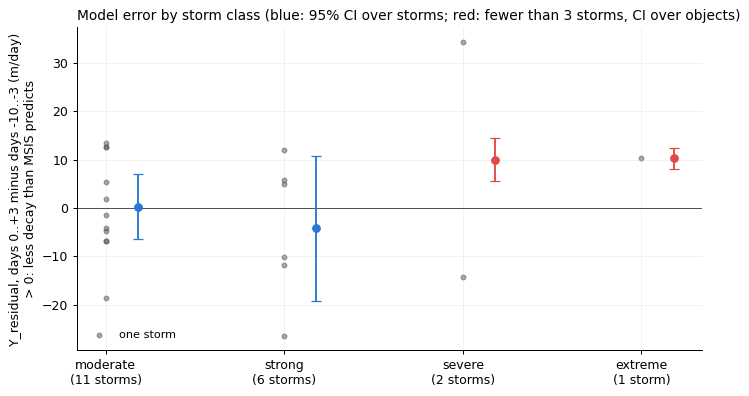

,mean,ci_lo,ci_hi,n_storms,ci_basis
storm_class,,,,,
moderate,0.3,-6.5,7.1,11,storms
strong,-4.2,-19.3,10.8,6,storms
severe,10.0,5.5,14.4,2,objects
extreme,10.3,8.1,12.4,1,objects


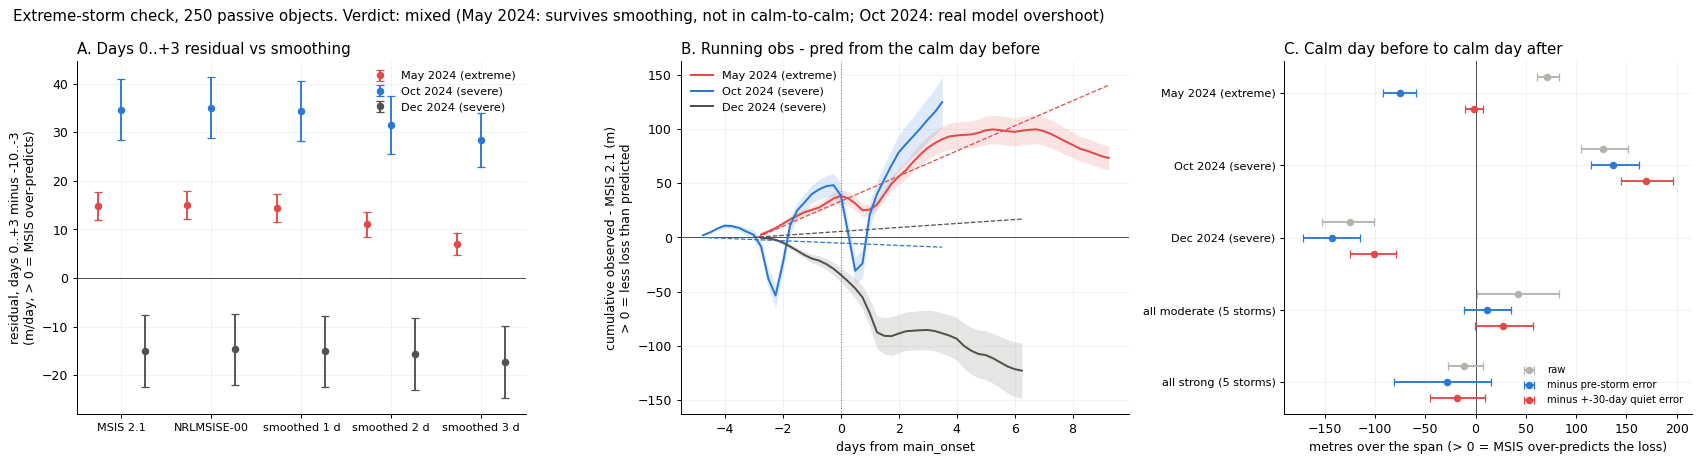

Verdict: mixed (May 2024: survives smoothing, not in calm-to-calm; Oct 2024: real model overshoot)


,ratio,ratio_lo,ratio_hi,diff_quiet_m,quiet_lo,quiet_hi
storm_id,,,,,,
4,0.91,0.90,0.92,-1.03,-10.35,7.04
11,0.86,0.84,0.87,169.48,144.14,196.71
13,1.19,1.17,1.22,-100.76,-124.97,-78.56


In [7]:
fig, N["class"] = rf.fig_class_error(table, storms)
show(fig)
display(N["class"].round(1))
extreme_out = timed("extreme-storm check", lambda: extreme_check.run(
    (table, storms, physics.load_msis_weather(), tles), log=lambda *a: None))
fig, N["extreme"] = rf.fig_extreme_check(extreme_out)
show(fig)
print("Verdict:", N["extreme"]["verdict"])
display(extreme_out["tables"][0]["storm"][["ratio", "ratio_lo", "ratio_hi", "diff_quiet_m", "quiet_lo", "quiet_hi"]].round(2))

## 7. Q2: storm vulnerability maps (causal forest)

A causal forest lets the DML effect vary by altitude, inclination and drag sensitivity, giving one effect per object and a
map over altitude and drag sensitivity. Dividing the outcome by drag sensitivity takes object size out and leaves the altitude
pattern. The forest's intervals ignore storm clustering, so the maps are read for their pattern, not their exact size.

vulnerability maps (vulnerability_map, +/- --per-drag): saved results loaded (13 files)


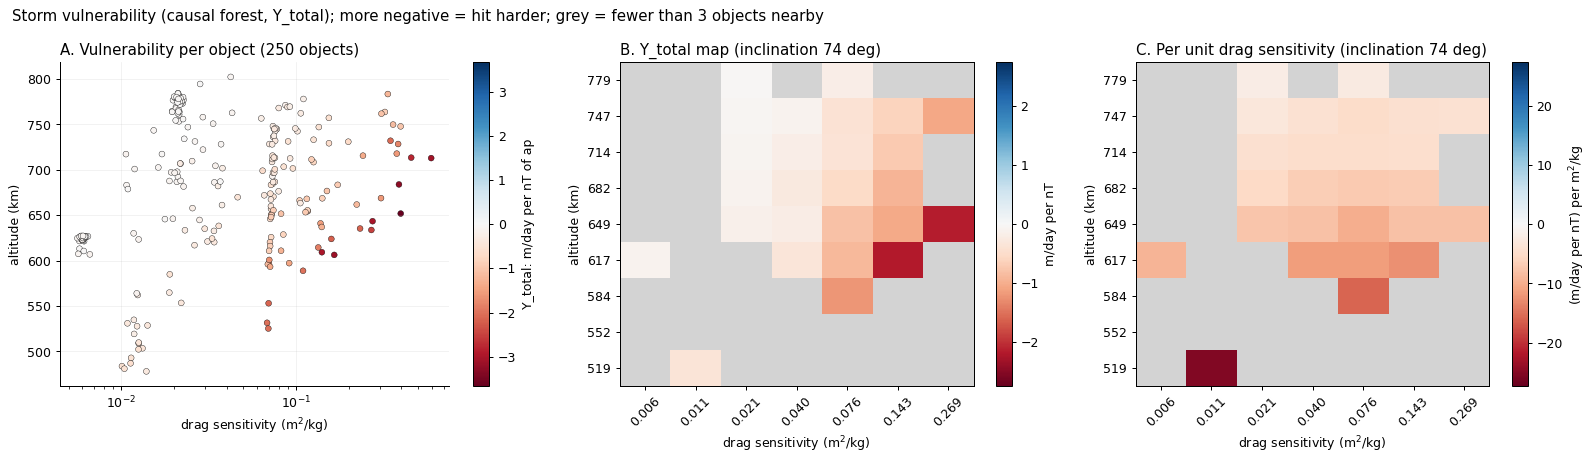

Y_total: importance {'alt_km': 0.101147402414827, 'inc_deg': 0.0065043736642534, 'drag_sensitivity': 0.8923482239209195}, seed stability min corr 0.986
Y_total_per_drag: importance {'alt_km': 0.9930581360708516, 'inc_deg': 0.0050907443619039, 'drag_sensitivity': 0.0018511195672446}, seed stability min corr 0.995
Per-drag effect -10.8 at 617 km -> -3.7 at 747 km (2.9x); cross-check correlation 0.96


In [8]:
slow_step("vulnerability maps (vulnerability_map, +/- --per-drag)",
          [DML / f"vulnerability_{k}_{y}.csv" for k in ("importance", "stats", "grid", "objects")
           for y in ("Y_total", "Y_residual", rf.PER_DRAG_OUTCOME)]
          + [DML / "vulnerability_per_drag_cross_check_summary.csv"],
          lambda: (vulnerability_map.main([]), vulnerability_map.main(["--per-drag"])))
fig, N["vuln"] = rf.fig_vulnerability()
show(fig)
for y in ("Y_total", rf.PER_DRAG_OUTCOME):
    v = N["vuln"][y]
    print(f"{y}: importance {v['importance']}, seed stability min corr {v['min_corr']:.3f}")
p = N["vuln"]["profile"]
print(f"Per-drag effect {p['effect_lo']:.1f} at {p['alt_lo']:.0f} km -> {p['effect_hi']:.1f} at {p['alt_hi']:.0f} km "
      f"({p['ratio']:.1f}x); cross-check correlation {N['vuln']['cross_corr']:.2f}")

## 8. Q3: operator offset ratio (Starlink)

No passive object flies near the Starlink shells, so each active satellite is compared with its own physics-predicted storm
loss instead of a twin. The offset ratio is 1 minus observed over predicted loss (1 = the whole loss undone), split into
ducking (during the storm) and recovery (10 days after), with a correction for the model's own error from the passive cohort.

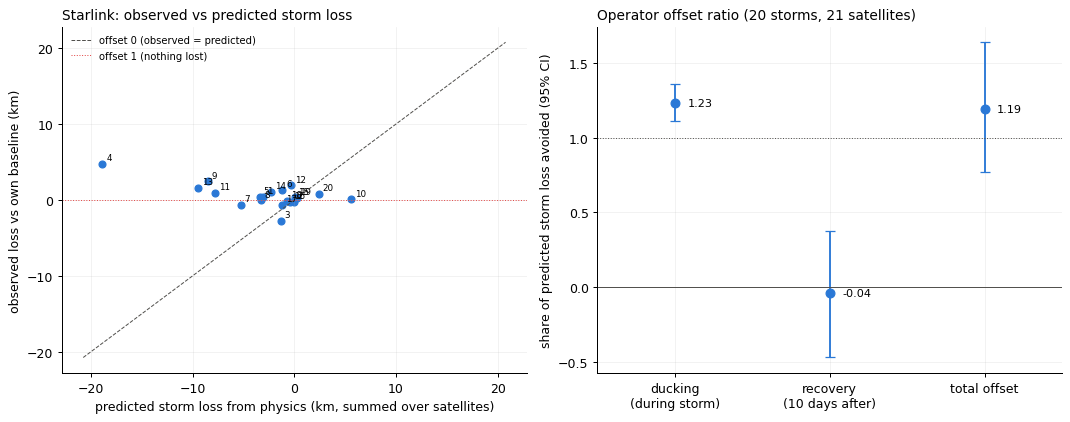

est  ci_lo  ci_hi  n_storms  n_objects
storms                               statistic                                            
all storms                           offset_total  1.17   0.97   1.36        20         21
                                     duck_part     1.16   1.05   1.27        20         21
                                     rec_part      0.01  -0.22   0.21        20         21
without 3,4,11                       offset_total  1.25   1.08   1.41        17         21
                                     duck_part     1.35   1.16   1.54        17         21
                                     rec_part     -0.10  -0.31   0.10        17         21
quiet ap (without 10,15,16,17,19,20) offset_total  1.15   1.04   1.26        14         21
                                     duck_part     1.00   0.91   1.09        14         21
                                     rec_part      0.15   0.04   0.28        14         21

In [9]:
fig, N["offset"] = rf.fig_offset(storms)
N["offset_storms"] = N["offset"].pop("storms_smaller")
show(fig)
N["offset_c"] = rf.offset_numbers()
om = pd.read_csv(CAUSAL / "offset_model.csv")
display(om[(om["prediction"] == "corrected") & om["statistic"].isin(["offset_total", "duck_part", "rec_part"])]
        .set_index(["storms", "statistic"])[["est", "ci_lo", "ci_hi", "n_storms", "n_objects"]].round(2))

## 9. Robustness

The DML estimates are refuted four ways: the high-altitude control (no air, so no effect expected), a random extra confounder,
100 shuffled storm timings, and dropping May + Oct 2024. The event study has placebo dates and its own high-altitude control
(section 4). `SENSITIVITY.md` reruns the event study without or with a looser Hampel filter and sweeps the Q3 orbit-change screen.

In [10]:
display(Markdown("\n".join(rf.refutations_text(N["dml"]))))
sens_path = REVIEW / "SENSITIVITY.md"
if sens_path.exists():
    # about 1 minute: rerun to a temporary file and compare with the saved report
    tmp = Path(tempfile.mkdtemp()) / "SENSITIVITY.md"
    with contextlib.redirect_stdout(io.StringIO()), warnings.catch_warnings():   # hide its progress log
        warnings.simplefilter("ignore")
        timed("sensitivity checks", lambda: sensitivity.main(["--out", str(tmp)]))
    same = tmp.read_text(encoding="utf-8") == sens_path.read_text(encoding="utf-8")
    print("SENSITIVITY.md rerun matches the saved file:", same)
    display(Markdown(sens_path.read_text(encoding="utf-8")))
else:
    print("results/review/SENSITIVITY.md not present (python -m src.sensitivity writes it)")

## Refutations (DML, m/day per nT)

- `Y_total` (main -0.393 (95% CI -0.527 to -0.268)):
  - High-altitude control (15 objects): -0.023 (95% CI -0.026 to -0.021); equivalence band +-0.197: PASS.
  - Random common cause: estimate moves -0.01 SE.
  - Shuffled storm timing (100 shifts): mean +0.004, SD 0.028; placebo p = 0.010 (0 of 100 as large as the real estimate).
  - Without May + Oct 2024 (storms 3,4,11): -0.503 (95% CI -0.642 to -0.361).
- `Y_residual` (main -0.050 (95% CI -0.141 to +0.047)):
  - High-altitude control (15 objects): -0.009 (95% CI -0.013 to -0.006); no equivalence test (main estimate covers 0).
  - Random common cause: estimate moves -0.00 SE.
  - Shuffled storm timing (100 shifts): mean +0.004, SD 0.025; placebo p = 0.059 (5 of 100 as large as the real estimate).
  - Without May + Oct 2024 (storms 3,4,11): -0.152 (95% CI -0.267 to -0.042).
  - Lag sweep without May + Oct 2024 (`Y_residual`): 0 h -0.155 (95% CI -0.266 to -0.051), 6 h -0.108 (95% CI -0.232 to +0.011), 12 h +0.002 (95% CI -0.121 to +0.121), 24 h +0.048 (95% CI -0.055 to +0.152).
- Model error by storm class in DML (`Y_residual`): moderate -0.133 (95% CI -0.247 to -0.010), strong -0.210 (95% CI -0.348 to -0.068), severe -0.037 (no CI, 2 storm(s)), extreme +0.021 (no CI, 1 storm(s)); severe + extreme vs the rest, exact permutation p = 0.32.


SENSITIVITY.md rerun matches the saved file: True


# Sensitivity checks

Made by `python -m src.sensitivity` from the frozen analysis table and the cached physics drivers. Nothing frozen changes: variants are rebuilt in memory.

## 1. Hampel removal by timing

Passive main sample (ecc < 0.01, drag sensitivity, alt < 1000 km) before the `tle_ok` filter; share of rows with `hampel_outlier = 1`. Event day = whole days from `main_onset` of the linked storm (-10..+20 window).

| event day | rows | flagged | share % |
|---|---|---|---|
| days -10..-3 | 41371 | 1649 | 4.0 |
| days -2..-1 | 17145 | 618 | 3.6 |
| day 0 | 7896 | 1488 | 18.8 |
| days 1..2 | 17191 | 1431 | 8.3 |
| days 3..20 | 56647 | 2959 | 5.2 |
| outside storm windows | 48310 | 2308 | 4.8 |
| all rows | 188560 | 10453 | 5.5 |

By storm class (rows inside storm windows):

| storm_class | rows | flagged | share % |
|---|---|---|---|
| moderate | 47516 | 2280 | 4.8 |
| strong | 52587 | 3280 | 6.2 |
| severe | 28381 | 2068 | 7.3 |
| extreme | 11766 | 517 | 4.4 |
| all storm windows | 140250 | 8145 | 5.8 |

Class by event day (share %):

| storm class | days -10..-3 | days -2..-1 | day 0 | days 1..2 | days 3..20 |
|---|---|---|---|---|---|
| moderate | 3.2 | 3.4 | 9.2 | 6.1 | 6.2 |
| strong | 3.4 | 1.9 | 25.8 | 12.4 | 5.5 |
| severe | 7.0 | 9.6 | 43.7 | 8.7 | 5.3 |
| extreme | 4.5 | 2.2 | 37.2 | 3.1 | 3.4 |

## 2. Event study without the Hampel filter

Days 0-2 mean effect, 95% wild cluster bootstrap CI by storm (999 draws, seed 0, same settings as the freeze, no placebo dates). TLE endpoint checks kept in every variant.

Check, rebuilt k = 3.5 table against the saved table (largest absolute difference): Y_total 0, Y_residual 0, hampel_outlier 0, tle_ok 0, drag_sensitivity 0

| variant | outcome | effect | rows | storms_used |
|---|---|---|---|---|
| frozen (k = 3.5) | Y_total | -14.1 (-19.8 to -8.4) | 3566 | 12 |
| frozen (k = 3.5) | Y_residual | +0.2 (-3.2 to +3.2) | 3566 | 12 |
| put back (k = 3.5 flags off, B kept) | Y_total | -16.0 (-23.4 to -8.4) | 4730 | 12 |
| put back (k = 3.5 flags off, B kept) | Y_residual | -0.3 (-5.2 to +4.3) | 4730 | 12 |
| no filter (B refitted on all rows) | Y_total | -16.0 (-23.4 to -8.3) | 4730 | 12 |
| no filter (B refitted on all rows) | Y_residual | -0.3 (-5.3 to +4.3) | 4730 | 12 |
| k = 5 (B refitted) | Y_total | -15.2 (-21.4 to -8.7) | 3867 | 12 |
| k = 5 (B refitted) | Y_residual | -0.3 (-4.1 to +3.0) | 3867 | 12 |

- `put back`: the k = 3.5 flags are not used in the sample, B and predictions stay as frozen.
- `no filter`: no Hampel flags anywhere, so B is also refitted on every quiet row.
- `k = 5`: flags at 5 robust SDs (instead of 3.5), B refitted without them.

## 3. Q3 orbit-change screen

`offset_model.run` (model-error corrected, all storms, quiet-ap check as in the freeze), screen = largest net altitude change in a 21-day window that still counts as station keeping. 1 km is the frozen setting. Pairs = satellite-storm pairs.

| max_change_km | total | ducking | recovery | n_pairs | n_storms | n_objects |
|---|---|---|---|---|---|---|
| 0.5 | +1.18 (+0.98 to +1.36) | +1.16 (+1.05 to +1.28) | +0.01 (-0.20 to +0.21) | 262 | 20 | 21 |
| 1.0 | +1.17 (+0.97 to +1.36) | +1.16 (+1.05 to +1.27) | +0.01 (-0.22 to +0.21) | 278 | 20 | 21 |
| 2.0 | +1.18 (+1.00 to +1.36) | +1.17 (+1.06 to +1.29) | +0.01 (-0.21 to +0.21) | 286 | 20 | 21 |

## 4. Pairs in the main Q3 run

278 satellite-storm pairs (21 satellites, 20 storms), screen 1 km.

## Reading

- Hampel removal is concentrated at the storm onset: 18.8% of day-0 rows are flagged against 4.0% on days -10..-3 and 5.5% overall; the highest day-0 share is in severe storms (44%).
- put back (k = 3.5 flags off, B kept): Y_total -16.0 (-23.4 to -8.4), Y_residual -0.3 (-5.2 to +4.3) (frozen -14.1 (-19.8 to -8.4), +0.2 (-3.2 to +3.2)).
- no filter (B refitted on all rows): Y_total -16.0 (-23.4 to -8.3), Y_residual -0.3 (-5.3 to +4.3) (frozen -14.1 (-19.8 to -8.4), +0.2 (-3.2 to +3.2)).
- k = 5 (B refitted): Y_total -15.2 (-21.4 to -8.7), Y_residual -0.3 (-4.1 to +3.0) (frozen -14.1 (-19.8 to -8.4), +0.2 (-3.2 to +3.2)).
- Q3 offset at 0.5 / 1 / 2 km: 1.18 / 1.17 / 1.18; the screen only changes the pair count (262 / 278 / 286).

## Summary table

Change % = (variant - frozen) / |frozen|. Where the frozen value is under 20% of its parent headline (Y_residual vs Y_total, the Q3 recovery part vs the total) the ratio explodes, so the change is measured against the parent headline instead (column `measured against`). Flag: |change| > 20%.

**Flags:** no headline moves by more than 20%.

| headline | variant | frozen | variant value | change % | measured against | CI includes 0 | flag |
|---|---|---|---|---|---|---|---|
| Y_total days 0-2 (m/day) | put back (k = 3.5 flags off, B kept) | -14.1 (-19.8 to -8.4) | -16.0 (-23.4 to -8.4) | -13.8 | own baseline | False -> False |  |
| Y_residual days 0-2 (m/day) | put back (k = 3.5 flags off, B kept) | +0.2 (-3.2 to +3.2) | -0.3 (-5.2 to +4.3) | -3.1 | parent headline | True -> True |  |
| Y_total days 0-2 (m/day) | no filter (B refitted on all rows) | -14.1 (-19.8 to -8.4) | -16.0 (-23.4 to -8.3) | -13.8 | own baseline | False -> False |  |
| Y_residual days 0-2 (m/day) | no filter (B refitted on all rows) | +0.2 (-3.2 to +3.2) | -0.3 (-5.3 to +4.3) | -3.1 | parent headline | True -> True |  |
| Y_total days 0-2 (m/day) | k = 5 (B refitted) | -14.1 (-19.8 to -8.4) | -15.2 (-21.4 to -8.7) | -7.7 | own baseline | False -> False |  |
| Y_residual days 0-2 (m/day) | k = 5 (B refitted) | +0.2 (-3.2 to +3.2) | -0.3 (-4.1 to +3.0) | -3.4 | parent headline | True -> True |  |
| Q3 corrected total offset | screen 0.5 km | +1.17 (+0.97 to +1.36) | +1.18 (+0.98 to +1.36) | +0.5 | own baseline | False -> False |  |
| Q3 ducking part | screen 0.5 km | +1.16 (+1.05 to +1.27) | +1.16 (+1.05 to +1.28) | +0.1 | own baseline | False -> False |  |
| Q3 recovery part | screen 0.5 km | +0.01 (-0.22 to +0.21) | +0.01 (-0.20 to +0.21) | +0.4 | parent headline | True -> True |  |
| Q3 corrected total offset | screen 2 km | +1.17 (+0.97 to +1.36) | +1.18 (+1.00 to +1.36) | +0.8 | own baseline | False -> False |  |
| Q3 ducking part | screen 2 km | +1.16 (+1.05 to +1.27) | +1.17 (+1.06 to +1.29) | +0.8 | own baseline | False -> False |  |
| Q3 recovery part | screen 2 km | +0.01 (-0.22 to +0.21) | +0.01 (-0.21 to +0.21) | +0.0 | parent headline | True -> True |  |


## 10. Headline numbers vs SUMMARY.md

Each headline number computed above is written in the same format as `results/review/SUMMARY.md` and compared with the value
found in that file. The cell fails if any of them differs; it also regenerates the whole SUMMARY.md text from this notebook's
numbers and checks that it is identical to the saved file.

In [11]:
summary = (REVIEW / "SUMMARY.md").read_text(encoding="utf-8")
ci, per_nt = rf._ci, rf._per_nt
r2 = lambda t: f"{t[0]:.2f} (95% CI {t[1]:.2f} to {t[2]:.2f})"
m0 = lambda t: f"{t[0]:+.0f} m (95% CI {t[1]:+.0f} to {t[2]:+.0f})"
CI = r"\S+ \(95% CI \S+ to \S+\)"
ev, d, x, o, oc, q = N["event"], N["dml"], N["extreme"], N["offset"], N["offset_c"], N["vuln"]
prof, rt, rr = q["profile"], d["refute"]["Y_total"], d["refute"]["Y_residual"]
rows = [  # (question, number, value computed here, regex with one group in SUMMARY.md)
    ("Q1", "total storm effect, days 0-2 (event study)", ci(ev["Y_total"], " m/day"), rf"total storm effect, days 0-2, (\S+ m/day \(95% CI \S+ to \S+\))"),
    ("Q1", "model error, days 0-2 (event study)", ci(ev["Y_residual"], " m/day"), rf"event-study model error days 0-2 (\S+ m/day \(95% CI \S+ to \S+\))"),
    ("Q1", "DML Y_total (m/day per nT)", per_nt(d["main"]["Y_total"]), rf"\(event study\); DML ({CI})"),
    ("Q1", "DML Y_residual (m/day per nT)", per_nt(d["main"]["Y_residual"]), rf"`Y_residual` \(main ({CI})\)"),
    ("Q1", "DML model error, moderate storms", per_nt(d["class"]["moderate"]), rf"moderate \(\d+ storms\) ({CI})"),
    ("Q1", "DML model error, strong storms", per_nt(d["class"]["strong"]), rf"strong \(\d+ storms\) ({CI})"),
    ("Q1", "lag 24 h, all storms", per_nt(rr["lags_all"][24]), rf"all storms 12 h {CI}, 24 h ({CI})"),
    ("Q1", "lag 24 h, without May + Oct 2024", per_nt(rr["lags_without"][24]), rf"\(storms [\d,]+\) 12 h {CI}, 24 h ({CI})"),
    ("Q1", "days 0..+3 model error, all storms", ci(x["all"], " m/day"), rf"days 0\.\.\+3 change across all \d+ storms (\S+ m/day \(95% CI \S+ to \S+\))"),
    ("Q1", "extreme-storm verdict", x["verdict"], r"verdict: \*\*(.+?)\*\*"),
    ("Q1", "Oct 2024 smoothed over-prediction", ci(x["storms"]["Oct 2024"]["smooth"], " m/day"), r"survives 3-day smoothing \((\S+ m/day \(95% CI \S+ to \S+\))\)"),
    ("Q1", "Oct 2024 calm-to-calm obs / pred", r2(x["storms"]["Oct 2024"]["ratio"]), rf"calm day after: observed / predicted ({CI})"),
    ("Q1", "Oct 2024 calm-to-calm minus quiet error", m0(x["storms"]["Oct 2024"]["quiet"]), r", (\S+ m \(95% CI \S+ to \S+\)) after removing"),
    ("Q1", "May 2024 smoothed excess", ci(x["storms"]["May 2024"]["smooth"], " m/day"), r"excess survives smoothing \((\S+ m/day \(95% CI \S+ to \S+\))\)"),
    ("Q1", "May 2024 calm-to-calm minus quiet error", m0(x["storms"]["May 2024"]["quiet"]), r"removed: (\S+ m \(95% CI \S+ to \S+\)) against"),
    ("Q1", "Dec 2024 calm-to-calm obs / pred", r2(x["storms"]["Dec 2024"]["ratio"]), rf"under-predicts the loss \(observed / predicted ({CI})\)"),
    ("Q2", "per-drag altitude pattern", f"{prof['effect_lo']:.1f} at {prof['alt_lo']:.0f} km to {prof['effect_hi']:.1f} at {prof['alt_hi']:.0f} km", r"Per-drag altitude pattern: (\S+ at \d+ km to \S+ at \d+ km)"),
    ("Q2", "per-drag ratio", f"{prof['ratio']:.1f}x", r"per m\^2/kg\), about (\S+x)"),
    ("Q2", "Y_total forest: drag-sensitivity importance", f"{q['Y_total']['importance']['drag_sensitivity']:.3f}", r"importance drag_sensitivity (\d\.\d+)"),
    ("Q2", "Y_total forest: 5-seed min correlation", f"{q['Y_total']['min_corr']:.3f}", r"5-seed map correlation min (\S+) "),
    ("Q2", "per-drag cross-check correlation", f"{q['cross_corr']:.2f}", r"supported cells\): correlation (\d\.\d+)"),
    ("Q3", "offset, model-error corrected", f"{oc['total'][0]:.2f}, 95% CI {oc['total'][1]:.2f}-{oc['total'][2]:.2f}", r"model-error corrected (\S+, 95% CI \S+);"),
    ("Q3", "ducking part (corrected)", r2(oc["duck"]), rf"ducking part ({CI}), recovery"),
    ("Q3", "recovery part (corrected)", f"{oc['rec'][0]:+.2f}, 95% CI {oc['rec'][1]:+.2f} to {oc['rec'][2]:+.2f}", r"recovery part (\S+, 95% CI \S+ to \S+), i\.e\."),
    ("Q3", "offset without noisy quiet-ap storms", r2(oc["quiet"]), rf"storms left\): ({CI})"),
    ("Q3", "offset without May / Oct 2024", r2(oc["without"]), rf"Without May / Oct 2024: ({CI})"),
    ("Q3", "offset, uncorrected (fig 7)", r2(o["offset_total"]), rf"Starlink total offset ({CI})"),
    ("Check", "DML high-altitude control, Y_total", per_nt(rt["high_alt"]), rf"High-altitude control \(\d+ objects\): ({CI}); equivalence"),
    ("Check", "shuffled storm timing p, Y_total", f"{rt['placebo_p']:.3f}", r"placebo p = (\S+) "),
    ("Check", "DML Y_total without May + Oct 2024", per_nt(rt["without"]), rf"Without May \+ Oct 2024 \(storms [\d,]+\): ({CI})"),
    ("Data", "storms (Dst < -50 nT)", str(N["catalog"]["n"]), r"`fig2_storm_catalog\.png`: (\d+) storms"),
    ("Data", "May 2024 cohort decay ratio", f"{N['may']['ratio']:.1f}x", r"\(first day after\), (\S+x)"),
    ("Physics", "held-out quiet residual", f"{N['physics']['holdout']:+.2f} m/day (SE {N['physics']['holdout_se']:.2f})", r"objects (\S+ m/day \(SE \S+\))"),
    ("Physics", "fitted vs catalog drag, Spearman rho", f"{N['valid']['rho']:.2f}", r"Spearman rho = (\S+) "),
    ("Physics", "fig 5 extreme storm model error", f"{N['class'].loc['extreme', 'mean']:+.1f}", r"Extreme \(one storm, CI over objects\) (\S+) "),
]
check = []
for qn, name, here, pattern in rows:
    m = re.search(pattern, summary)
    check.append({"question": qn, "number": name, "this notebook": here,
                  "SUMMARY.md": m.group(1) if m else "NOT FOUND", "match": bool(m) and m.group(1) == here})
check = pd.DataFrame(check)
with pd.option_context("display.max_colwidth", 80):
    display(check)
bad = check[~check["match"]]
assert bad.empty, f"{len(bad)} headline numbers differ from SUMMARY.md:\n{bad.to_string()}"
print(f"All {len(check)} headline numbers match SUMMARY.md.")

regenerated = rf.summary_text(N)
assert regenerated == summary, "SUMMARY.md text regenerated from this notebook differs from the saved file"
print("SUMMARY.md regenerated from this notebook's numbers is identical to the saved file.")

,question,number,this notebook,SUMMARY.md,match
0,Q1,"total storm effect, days 0-2 (event study)",-14.1 m/day (95% CI -19.8 to -8.4),-14.1 m/day (95% CI -19.8 to -8.4),True
1,Q1,"model error, days 0-2 (event study)",+0.2 m/day (95% CI -3.2 to +3.2),+0.2 m/day (95% CI -3.2 to +3.2),True
2,Q1,DML Y_total (m/day per nT),-0.393 (95% CI -0.527 to -0.268),-0.393 (95% CI -0.527 to -0.268),True
3,Q1,DML Y_residual (m/day per nT),-0.050 (95% CI -0.141 to +0.047),-0.050 (95% CI -0.141 to +0.047),True
4,Q1,"DML model error, moderate storms",-0.133 (95% CI -0.247 to -0.010),-0.133 (95% CI -0.247 to -0.010),True
5,Q1,"DML model error, strong storms",-0.210 (95% CI -0.348 to -0.068),-0.210 (95% CI -0.348 to -0.068),True
6,Q1,"lag 24 h, all storms",+0.117 (95% CI +0.035 to +0.200),+0.117 (95% CI +0.035 to +0.200),True
7,Q1,"lag 24 h, without May + Oct 2024",+0.048 (95% CI -0.055 to +0.152),+0.048 (95% CI -0.055 to +0.152),True
8,Q1,"days 0..+3 model error, all storms",+0.8 m/day (95% CI -5.8 to +7.4),+0.8 m/day (95% CI -5.8 to +7.4),True
9,Q1,extreme-storm verdict,"mixed (May 2024: survives smoothing, not in calm-to-calm; Oct 2024: real mod...","mixed (May 2024: survives smoothing, not in calm-to-calm; Oct 2024: real mod...",True


All 35 headline numbers match SUMMARY.md.
SUMMARY.md regenerated from this notebook's numbers is identical to the saved file.


In [12]:
total = time.time() - T_START
print(f"Total run time: {total / 60:.1f} min (FAST = {FAST})")
display(pd.Series(TIMES, name="seconds").round(1).to_frame())

Total run time: 3.8 min (FAST = True)


,seconds
build analysis table,0.0
load table,0.4
event study + offset model (causal_run),0.0
DML (dml_run),0.0
"DML refutations (dml_refute, 100 shifts)",0.0
DML by storm class (storm_class),0.0
extreme-storm check,139.2
"vulnerability maps (vulnerability_map, +/- --per-drag)",0.0
sensitivity checks,74.3
